# Project: N-Body Gravitational Simulation & Numerical Stability Analysis

This project aims to develop a numerical simulation of gravitationally interacting bodies using Python, beginning with a two-body Sun–Earth system and progressively extending it to multiple bodies. The project will investigate how different numerical integration methods and timestep sizes affect the accuracy and stability of the simulated orbits, using quantities such as orbital trajectories, total energy and angular momentum to assess the performance of the simulation.


#### 1\. Import the necessary libraries



In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

%matplotlib inline

#### 2\. Define physical constants & set up the initial positions and velocities using a 2D simulation



In [37]:
# Define standard astronomical and physical constants
G = 6.67430E-11
M_sun = 1.989E30
M_earth = 5.972E24

# Positions the Sun at the coordinate origin and Earth at 1 Astronomical Unit (AU) along the x-axis
r_sun = np.array([0, 0])
r_earth = np.array([1.496E11, 0])

# Sun is stationary; Earth starts to the right, moves upward (establishing a circular velocity) and is pulled by gravity
v_sun = np.array([0, 0])
v_earth = np.array([0, 29780])

# Separation vector from the Sun to the Earth can be computed, including its magnitude
r_sep = r_earth - r_sun
r_sep_mag = np.linalg.norm(r_sep)

#### 3\. Calculate the gravitational force and acceleration



$$ \begin{equation*}
\begin{split}
\mathbf{F}_{Earth} = \frac{G M_{Sun} M_{Earth}}{r^2} \hat{\mathbf{r}}, \qquad \mathbf{F} = m\mathbf{a}, \qquad \text \qquad \mathbf{F}_{Sun} = -\mathbf{F}_{Earth}
\end{split}
\end{equation*} $$





These principles form the physical foundation of the simulation. Newton's law of gravitation determines the attractive force vector between the bodies. Newton's second law (\(\mathbf{F}=m\mathbf{a}\)) translates this force into acceleration, which directly changes the Earth's velocity. Finally, Newton's third law (\(\mathbf{F}_{Sun} = -\mathbf{F}_{Earth}\)) ensures that an equal and opposite reaction force simultaneously pulls the Sun toward the Earth. Together, these laws provide the exact accelerations needed to advance the system in time.


In [38]:
# Calculates gravitational force vector using the Sun-to-Earth unit vector
F_mag = (G * M_sun * M_earth) / (r_sep_mag**2)
r_sep_unit = r_sep / r_sep_mag 
F_vec = -F_mag * r_sep_unit
print(F_vec)

# Using Newton's 2nd law to convert force into acceleration
a_earth = F_vec / M_earth
a_sun = -F_vec / M_sun # Newton's 3rd law

[-3.54239608e+22 -0.00000000e+00]


#### 4\. Simulate a year with a chosen timestep and update the velocity and position



\begin{equation*}
\begin{split}
\mathbf{v}_{new} = \mathbf{v}_{old} + \mathbf{a}_{old} {\Delta}t \\
\mathbf{r}_{new} = \mathbf{r}_{old} + \mathbf{v}_{old} {\Delta}t
\end{split}
\end{equation*}



These equations represent Euler's method, a numerical integration technique used to simulate the step-by-step motion of the bodies over small intervals of time \(\Delta t\). In this N-body project, Newton's law of gravitation first determines the current acceleration \(\mathbf{a}_{old}\) based on the distances between the masses. Euler's method then assumes this acceleration and the current velocity \(\mathbf{v}_{old}\) remain constant during the timestep, multiplying them by \(\Delta t\) to compute the new velocity \(\mathbf{v}_{new}\) and position \(\mathbf{r}_{new}\). Repeating this quick linear update over many consecutive steps maps out the system's entire orbital paths.


In [39]:
timestep = 3600 # Experiment with different values
t_tot = 3.156e7 # One year

# Magnitude of Earth and Sun velocities
v_earth_mag = np.linalg.norm(v_earth)
v_sun_mag = np.linalg.norm(v_sun)
    
# Calculate the initial total energy
KE_earth = 0.5 * M_earth * (v_earth_mag**2)
KE_sun = 0.5 * M_sun * (v_sun_mag**2)
PE = -(G * M_sun * M_earth)/r_sep_mag
E0 = KE_earth + KE_sun + PE

# Calculate the initial angular momentum
Lz_earth = M_earth*(r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
Lz_sun = M_sun*(r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
Lz0 = Lz_earth + Lz_sun

# Initialise simulation records for positions and invariants
earth_pos = [r_earth.copy()]
sun_pos = [r_sun.copy()]
E_tots = [E0]
Lz_tots = [Lz0]

# Euler's method - this calculates what happens over an entire year, one timestep at a time
for i in range(int(t_tot / timestep)):  
    r_sep = r_earth - r_sun
    r_sep_mag = np.linalg.norm(r_sep)
    
    # F_vec is the attractive force acting on Earth and the negative sign flips the vector direction so that it points back towards the Sun        (opposite to the Sun-to-Earth r_sep_unit vector)
    F_mag = (G * M_sun * M_earth) / (r_sep_mag**2)
    r_sep_unit = r_sep / r_sep_mag
    F_vec = -F_mag * r_sep_unit
    
    a_earth = F_vec / M_earth
    a_sun = -F_vec / M_sun
    
    # Calculate new velocities/positions
    v_earth1 = v_earth + (a_earth * timestep)
    r_earth1 = r_earth + (v_earth * timestep)
    v_sun1 = v_sun + (a_sun * timestep)
    r_sun1 = r_sun + (v_sun * timestep)
    
    # Update current velocities/positions
    v_earth = v_earth1
    r_earth = r_earth1
    v_sun = v_sun1
    r_sun = r_sun1
    
    # Store current positions
    earth_pos.append(r_earth.copy())
    sun_pos.append(r_sun.copy())
    
    # Magnitude of new Earth and Sun velocities
    v_earth_mag = np.linalg.norm(v_earth)
    v_sun_mag = np.linalg.norm(v_sun)
    
    # The total energy of the two-body system is computed, then plotted as a function of time
    KE_earth = 0.5 * M_earth * (v_earth_mag**2)
    KE_sun = 0.5 * M_sun * (v_sun_mag**2)
    PE = -(G * M_sun * M_earth)/r_sep_mag
    E_tot = KE_earth + KE_sun + PE
    E_tots.append(E_tot.copy())
    
    # For a 2D simulation, the z-component of angular momentum can be calculated, then plotted as a function of time
    Lz_earth = M_earth*(r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
    Lz_sun = M_sun*(r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
    Lz_tot = Lz_earth + Lz_sun
    Lz_tots.append(Lz_tot)

#### 5\. Plot the orbit



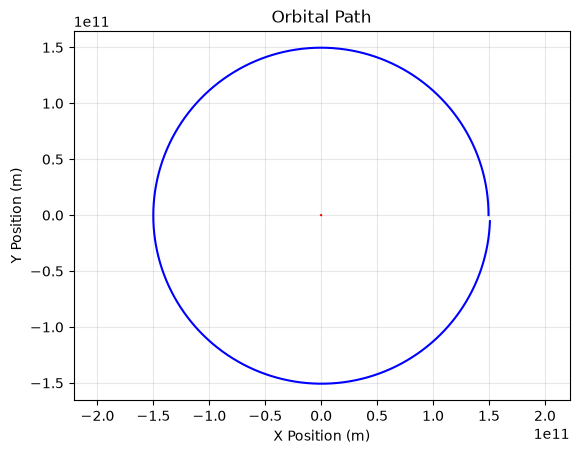

In [40]:
# Convert the list of positions into a NumPy array for use of 2D indexing
earth_positions = np.array(earth_pos)
sun_positions = np.array(sun_pos)

# : takes every row while 0 or 1 selects the column
plt.plot(earth_positions[:, 0], earth_positions[:, 1], color='b')
plt.plot(sun_positions[:, 0], sun_positions[:, 1], color='r') # Plotting the Sun's position shows the geometry of the system
plt.title('Orbital Path')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.grid(True, alpha=0.3)
plt.axis("equal") # Ensures the orbit is not visually stretched
plt.show()

The open, spiraling path of the orbit demonstrates the primary limitation of Euler's method. The linear accumulation of numerical errors prevents the orbit from closing cleanly, indicating a lack of long-term conservation of energy and angular momentum.


#### 6\. Check that results make physical sense and plot the energy and angular momentum as a function of time



31949967.69345517


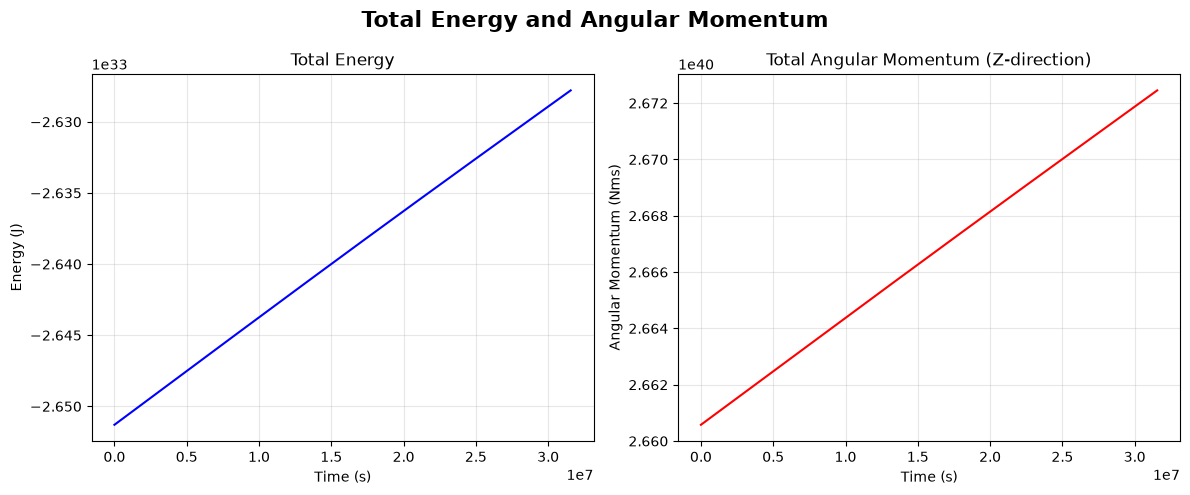

In [41]:
T = 2*np.pi*np.sqrt((r_earth[0])**3/(G*M_sun))
print(T) # The actual time it takes for Earth to orbit the Sun is T≈3.156E7 s (365.25 days)

# Convert the lists into a NumPy array for use of 2D indexing
E_tots_arr = np.array(E_tots)
Lz_tots_arr = np.array(Lz_tots)

# Time values are created from the number of given measurements
times_E = np.arange(len(E_tots)) * timestep
times_L = np.arange(len(Lz_tots)) * timestep

# Create two side-by-side plots in a single figure and add an overall title
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Total Energy and Angular Momentum', fontsize=16, fontweight='bold', ha='center')

# Left Plot: Energy
axes[0].plot(times_E , E_tots_arr, 'b-')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Energy (J)')
axes[0].set_title('Total Energy')
axes[0].grid(True, alpha=0.3)

# Right Plot: Angular momentum
axes[1].plot(times_L, Lz_tots_arr, 'r-')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Angular Momentum (Nms)')
axes[1].set_title('Total Angular Momentum (Z-direction)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout() # Prevents overlapping labels
plt.show()

The calculated orbital period closely matches the actual length of an Earth year, confirming that the initial setup and mass configurations accurately reproduce a stable planetary orbit.

The total energy and angular momentum gradually deviate from their initial values over time, showing that the simulation does not perfectly conserve these physical quantities. These deviations reflect numerical errors in the integration.


As the timestep is increased, the orbit loses its circular shape, and key physical invariants, such as the total energy and angular momentum, begin to drift, indicating a significant loss of numerical accuracy and conservation. At excessively large steps (e.g. $∆t$ = 1 day = 86400 s), the system's accuracy degrades so significantly that even massive central bodies like the Sun will noticeably drift away from their expected positions.


#### 7\. Investigating the timestep size and plotting the relative energy error



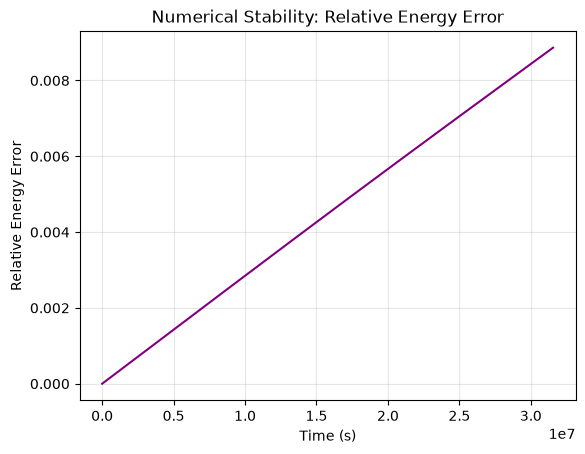

In [42]:
# The relative energy error can be quantified
rel_energy_err = np.abs(E_tots_arr - E0) / np.abs(E0)
plt.plot(times_E, rel_energy_err, color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Relative Energy Error')
plt.title('Numerical Stability: Relative Energy Error')
plt.grid(True, alpha=0.3)
plt.show()

The relative energy error increases relatively smoothly over time, indicating a gradual accumulation of energy error throughout the simulation. This suggests that the numerical method becomes less accurate as the simulation progresses.

As the timestep increases, the relative energy error becomes larger and grows more rapidly with time, showing that larger timesteps reduce the accuracy and stability of the Euler method.


#### 8\. Implement Fourth-order Runge-Kutta (RK4)




$$
\begin{equation*}
\begin{split}
y_{n+1} = y_{n} + \frac{{\Delta}t}{6} (k_1 + 2k_2 + 2k_3 + k_4)
\end{split}
\end{equation*}
$$



Instead of estimating the evolution from the derivative at only the beginning of each timestep, fourth-order Runge-Kutta (RK4) evaluates the derivative several times within the timestep. It evaluates the derivative at:

1. the **start** of the timestep
2. roughly the **middle**
3. another estimate of the **middle**
4. the **end**

It then takes a weighted combination of those four estimates, with the standard RK4 combination expressed above, where $y$ represents the whole state (positions **and** velocities).



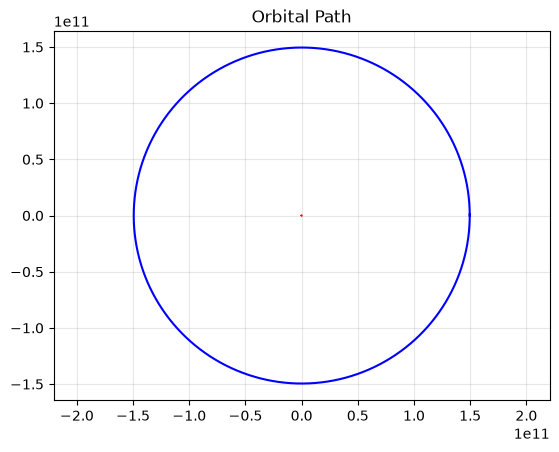

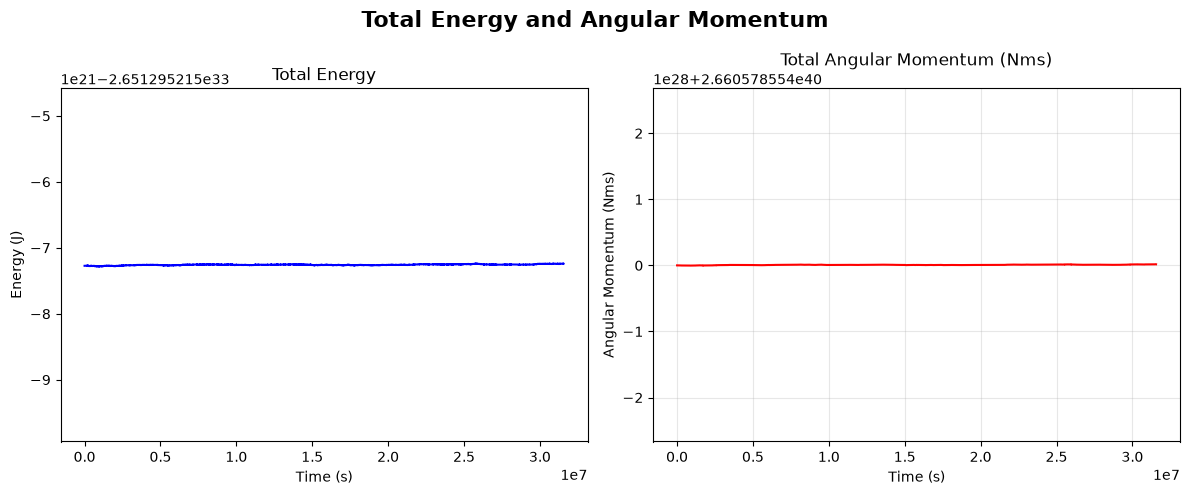

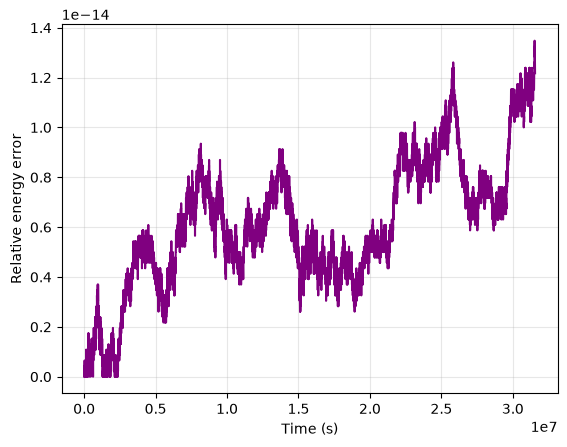

In [43]:
# Initialise known quantities
G = 6.67430E-11
M_sun = 1.989E30
M_earth = 5.972E24

r_sun = np.array([0, 0])
r_earth = np.array([1.496E11, 0])
v_sun = np.array([0, 0])
v_earth = np.array([0, 29780])

timestep = 3600 # Experiment with different values
t_tot = 3.156e7 # One year

# Earth and Sun velocity magnitudes
v_earth_mag = np.linalg.norm(v_earth)
v_sun_mag = np.linalg.norm(v_sun)
r_sep = r_earth - r_sun
r_sep_mag = np.linalg.norm(r_sep)

# Define initial total energy and total angular momentum
KE_earth = 0.5 * M_earth * (v_earth_mag**2)
KE_sun = 0.5 * M_sun * (v_sun_mag**2)
PE = -(G * M_sun * M_earth)/r_sep_mag
E0 = KE_earth + KE_sun + PE

Lz_earth = M_earth*(r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
Lz_sun = M_sun*(r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
Lz0 = Lz_earth + Lz_sun

# Initialise simulation records for positions and invariants 
earth_pos = [r_earth.copy()]
sun_pos = [r_sun.copy()]
E_tots = [E0]
Lz_tots = [Lz0]

# For this method, a function is created that takes the current state and returns the derivatives
def derivatives(r_sun, r_earth, v_sun, v_earth):
    r_sep = r_earth - r_sun
    r_sep_mag = np.linalg.norm(r_sep)
    
    F_mag = (G * M_sun * M_earth) / (r_sep_mag**2)
    r_sep_unit = r_sep / r_sep_mag
    F_vec = -F_mag * r_sep_unit
    
    a_earth = F_vec / M_earth
    a_sun = -F_vec / M_sun
    
    return v_sun, v_earth, a_sun, a_earth

# This RK4 loop can then call that function four times
for i in range(int(t_tot / timestep)):   
    # 1. Current state
    k1 = derivatives(r_sun, r_earth, v_sun, v_earth)
    k1_v_sun, k1_v_earth, k1_a_sun, k1_a_earth = k1

    r_sun_half = r_sun + 0.5 * timestep * k1_v_sun
    r_earth_half = r_earth + 0.5 * timestep * k1_v_earth
    v_sun_half = v_sun + 0.5 * timestep * k1_a_sun
    v_earth_half = v_earth + 0.5 * timestep * k1_a_earth
    
    # 2. First midpoint state
    k2 = derivatives(r_sun_half, r_earth_half, v_sun_half, v_earth_half)
    k2_v_sun, k2_v_earth, k2_a_sun, k2_a_earth = k2
    
    r_sun_half2 = r_sun + 0.5 * timestep * k2_v_sun
    r_earth_half2 = r_earth + 0.5 * timestep * k2_v_earth
    v_sun_half2 = v_sun + 0.5 * timestep * k2_a_sun
    v_earth_half2 = v_earth + 0.5 * timestep * k2_a_earth
    
    # 3. Second midpoint state
    k3 = derivatives(r_sun_half2, r_earth_half2, v_sun_half2, v_earth_half2)
    k3_v_sun, k3_v_earth, k3_a_sun, k3_a_earth = k3
    
    r_sun_end = r_sun + timestep * k3_v_sun
    r_earth_end = r_earth + timestep * k3_v_earth
    v_sun_end = v_sun + timestep * k3_a_sun
    v_earth_end = v_earth + timestep * k3_a_earth
    
    # 4. End state
    k4 = derivatives(r_sun_end, r_earth_end, v_sun_end, v_earth_end)
    k4_v_sun, k4_v_earth, k4_a_sun, k4_a_earth = k4
    
    # Weighted combination of the 4 states
    r_earth = r_earth + (timestep / 6) * (k1_v_earth + 2*k2_v_earth + 2*k3_v_earth + k4_v_earth)
    v_earth = v_earth + (timestep / 6) * (k1_a_earth + 2*k2_a_earth + 2*k3_a_earth + k4_a_earth)
    r_sun = r_sun + (timestep / 6) * (k1_v_sun + 2*k2_v_sun + 2*k3_v_sun + k4_v_sun)
    v_sun = v_sun + (timestep / 6) * (k1_a_sun + 2*k2_a_sun + 2*k3_a_sun + k4_a_sun)
    
    # Ends similar to Euler's method
    r_sep = r_earth - r_sun
    r_sep_mag = np.linalg.norm(r_sep)
    
    earth_pos.append(r_earth.copy())
    sun_pos.append(r_sun.copy())
    
    v_earth_mag = np.linalg.norm(v_earth)
    v_sun_mag = np.linalg.norm(v_sun)
    
    KE_earth = 0.5 * M_earth * (v_earth_mag**2)
    KE_sun = 0.5 * M_sun * (v_sun_mag**2)
    PE = -(G * M_sun * M_earth)/r_sep_mag
    E_tot = KE_earth + KE_sun + PE
    E_tots.append(E_tot.copy())
    
    Lz_earth = M_earth * (r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
    Lz_sun = M_sun * (r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
    Lz_tot = Lz_earth + Lz_sun
    Lz_tots.append(Lz_tot)

earth_positions = np.array(earth_pos)
sun_positions = np.array(sun_pos)

# : takes every row while 0 or 1 selects the column
plt.plot(earth_positions[:, 0], earth_positions[:, 1], color='b')
plt.plot(sun_positions[:, 0], sun_positions[:, 1], color='r') # Plotting the Sun's position shows the geometry of the system
plt.title('Orbital Path')
plt.grid(True, alpha=0.3)
plt.axis("equal") # Ensures the orbit is not visually stretched
plt.show()

E_tots_arr = np.array(E_tots)
Lz_tots_arr = np.array(Lz_tots)

# Time values are created from the number of given measurements
times_E = np.arange(len(E_tots)) * timestep
times_L = np.arange(len(Lz_tots)) * timestep

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Total Energy and Angular Momentum', fontsize=16, fontweight='bold', ha='center')

# Energy, angular momentum and relative energy error are plotted as a function of time
axes[0].plot(times_E , E_tots_arr, 'b-')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Energy (J)')
axes[0].set_title('Total Energy')
axes[1].plot(times_L, Lz_tots_arr, 'r-')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Angular Momentum (Nms)')
axes[1].set_title('Total Angular Momentum (Nms)')
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()

rel_energy_err = np.abs(E_tots_arr - E0) / np.abs(E0)
plt.plot(times_E, rel_energy_err, color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Relative energy error')
plt.grid(True, alpha=0.3)
plt.show()

Unlike Euler's method, which produced a spiralling orbit due to accumulated numerical errors, RK4 produces a more stable, approximately closed orbit. This demonstrates its improved accuracy for the chosen timestep.

The total energy and angular momentum remain approximately constant during the RK4 simulation, with smaller deviations than in the Euler results. This indicates that RK4 better preserves the system's physical behaviour, compared with Euler's method.

Unlike Euler's relatively smooth, steadily increasing energy error, RK4 shows small spikes in relative energy error. However, these remain comparatively small, indicating that RK4 generally maintains better energy accuracy over the simulated year.



#### 9\. Extend to three bodies



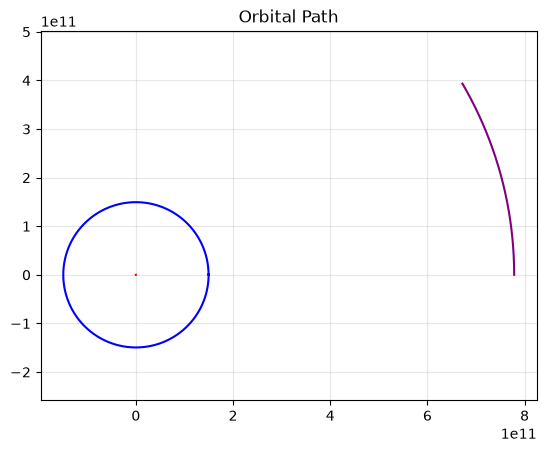

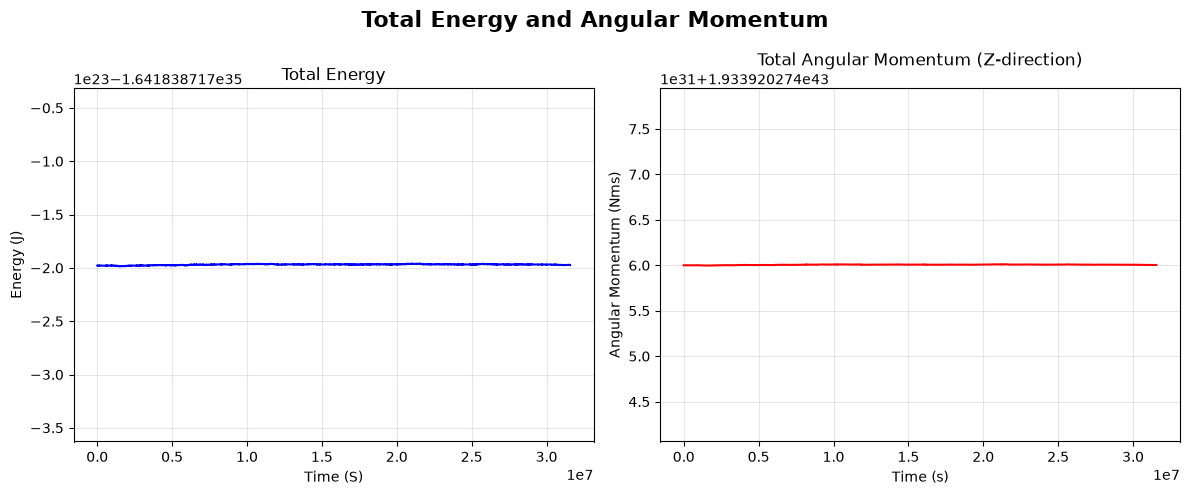

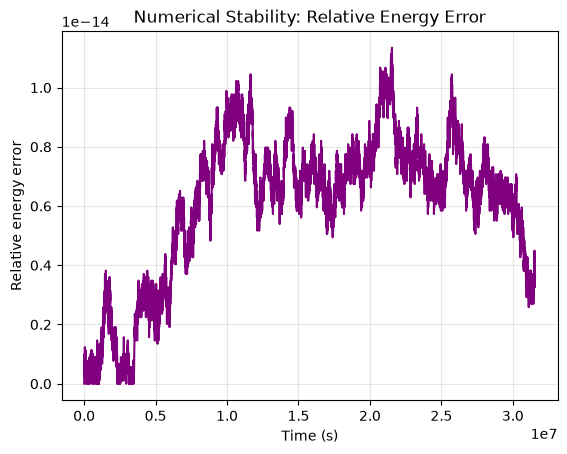

In [44]:
# Define standard astronomical and physical constants as well as time values
G = 6.67430E-11
M_sun = 1.989E30
M_earth = 5.972E24
M_jupiter = 1.898E27
timestep = 3600 
t_tot = 3.156e7

r_sun = np.array([0, 0])
r_earth = np.array([1.496E11, 0])
r_jupiter = np.array([5.204 * 1.496E11, 0])
v_sun = np.array([0, 0])
v_earth = np.array([0, 29780])
v_jupiter = np.array([0, 13070])

v_earth_mag = np.linalg.norm(v_earth)
v_sun_mag = np.linalg.norm(v_sun)
v_jupiter_mag = np.linalg.norm(v_jupiter)

r_sep1 = r_earth - r_sun
r_sep1_mag = np.linalg.norm(r_sep1)
r_sep2 = r_jupiter - r_sun
r_sep2_mag = np.linalg.norm(r_sep2)
r_sep3 = r_jupiter - r_earth
r_sep3_mag = np.linalg.norm(r_sep3)

# Calculate the initial total energy
KE_earth = 0.5 * M_earth * (v_earth_mag**2)
KE_sun = 0.5 * M_sun * (v_sun_mag**2)
KE_jupiter = 0.5 * M_jupiter * (v_jupiter_mag**2)
PE_earth = -(G * M_sun * M_earth) / r_sep1_mag
PE_jupiter = -(G * M_sun * M_jupiter) / r_sep2_mag
PE_ej = -(G * M_earth * M_jupiter) / r_sep3_mag
E0 = KE_earth + KE_sun + KE_jupiter + PE_earth + PE_jupiter + PE_ej

# Calculate the initial angular momentum
Lz_earth = M_earth * (r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
Lz_sun = M_sun * (r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
Lz_jupiter = M_jupiter * (r_jupiter[0] * v_jupiter[1] - r_jupiter[1] * v_jupiter[0])
Lz0 = Lz_earth + Lz_sun + Lz_jupiter

# Store the initial conditions and initialise empty lists
earth_pos = [r_earth.copy()]
sun_pos = [r_sun.copy()]
jupiter_pos = [r_jupiter.copy()]
E_tots = [E0]
Lz_tots = [Lz0]

# Same derivatives function previously defined but includes the position and velocity of Jupiter
def derivatives(r_sun, r_earth, r_jupiter, v_sun, v_earth, v_jupiter):
    r_sep1 = r_earth - r_sun
    r_sep1_mag = np.linalg.norm(r_sep1)
    
    r_sep2 = r_jupiter - r_sun
    r_sep2_mag = np.linalg.norm(r_sep2)
    
    r_sep3 = r_jupiter - r_earth
    r_sep3_mag = np.linalg.norm(r_sep3)
    
    F_mag1 = (G * M_sun * M_earth) / (r_sep1_mag**2)
    r_sep1_unit = r_sep1 / r_sep1_mag
    F_vec1 = -F_mag1 * r_sep1_unit
    
    F_mag2 = (G * M_sun * M_jupiter) / (r_sep2_mag**2)
    r_sep2_unit = r_sep2 / r_sep2_mag
    F_vec2 = -F_mag2 * r_sep2_unit
    
    F_mag3 = (G * M_earth * M_jupiter) / (r_sep3_mag**2)
    r_sep3_unit = r_sep3 / r_sep3_mag
    F_vec3 = F_mag3 * r_sep3_unit
    
    a_earth = (F_vec1 + F_vec3) / M_earth
    a_sun = -(F_vec1 + F_vec2) / M_sun
    a_jupiter = (F_vec2 - F_vec3) / M_jupiter
    
    return v_sun, v_earth, v_jupiter, a_sun, a_earth, a_jupiter

# RK4 loop, which accounts for Jupiter's position and velocity
for i in range(int(t_tot / timestep)):   
    k1 = derivatives(r_sun, r_earth, r_jupiter, v_sun, v_earth, v_jupiter)
    k1_v_sun, k1_v_earth, k1_v_jupiter, k1_a_sun, k1_a_earth, k1_a_jupiter = k1

    r_sun_half = r_sun + 0.5 * timestep * k1_v_sun
    r_earth_half = r_earth + 0.5 * timestep * k1_v_earth
    r_jupiter_half = r_jupiter + 0.5 * timestep * k1_v_jupiter
    
    v_sun_half = v_sun + 0.5 * timestep * k1_a_sun
    v_earth_half = v_earth + 0.5 * timestep * k1_a_earth
    v_jupiter_half = v_jupiter + 0.5 * timestep * k1_a_jupiter
    
    k2 = derivatives(r_sun_half, r_earth_half, r_jupiter_half, v_sun_half, v_earth_half, v_jupiter_half)
    k2_v_sun, k2_v_earth, k2_v_jupiter, k2_a_sun, k2_a_earth, k2_a_jupiter = k2
    
    r_sun_half2 = r_sun + 0.5 * timestep * k2_v_sun
    r_earth_half2 = r_earth + 0.5 * timestep * k2_v_earth
    r_jupiter_half2 = r_jupiter + 0.5 * timestep * k2_v_jupiter
    
    v_sun_half2 = v_sun + 0.5 * timestep * k2_a_sun
    v_earth_half2 = v_earth + 0.5 * timestep * k2_a_earth
    v_jupiter_half2 = v_jupiter + 0.5 * timestep * k2_a_jupiter
    
    k3 = derivatives(r_sun_half2, r_earth_half2, r_jupiter_half2, v_sun_half2, v_earth_half2, v_jupiter_half2)
    k3_v_sun, k3_v_earth, k3_v_jupiter, k3_a_sun, k3_a_earth, k3_a_jupiter = k3
    
    r_sun_end = r_sun + timestep * k3_v_sun
    r_earth_end = r_earth + timestep * k3_v_earth
    r_jupiter_end = r_jupiter + timestep * k3_v_jupiter
    
    v_sun_end = v_sun + timestep * k3_a_sun
    v_earth_end = v_earth + timestep * k3_a_earth
    v_jupiter_end = v_jupiter + timestep * k3_a_jupiter
    
    k4 = derivatives(r_sun_end, r_earth_end, r_jupiter_end, v_sun_end, v_earth_end, v_jupiter_end)
    k4_v_sun, k4_v_earth, k4_v_jupiter, k4_a_sun, k4_a_earth, k4_a_jupiter = k4
    
    r_earth = r_earth + (timestep / 6) * (k1_v_earth + 2*k2_v_earth + 2*k3_v_earth + k4_v_earth)
    v_earth = v_earth + (timestep / 6) * (k1_a_earth + 2*k2_a_earth + 2*k3_a_earth + k4_a_earth)
    
    r_sun = r_sun + (timestep / 6) * (k1_v_sun + 2*k2_v_sun + 2*k3_v_sun + k4_v_sun)
    v_sun = v_sun + (timestep / 6) * (k1_a_sun + 2*k2_a_sun + 2*k3_a_sun + k4_a_sun)
    
    r_jupiter = r_jupiter + (timestep / 6) * (k1_v_jupiter + 2*k2_v_jupiter + 2*k3_v_jupiter + k4_v_jupiter)
    v_jupiter = v_jupiter + (timestep / 6) * (k1_a_jupiter + 2*k2_a_jupiter + 2*k3_a_jupiter + k4_a_jupiter)
    
    # Current separations after the RK4 update
    r_sep1 = r_earth - r_sun
    r_sep1_mag = np.linalg.norm(r_sep1)
    
    r_sep2 = r_jupiter - r_sun
    r_sep2_mag = np.linalg.norm(r_sep2)
    
    r_sep3 = r_jupiter - r_earth
    r_sep3_mag = np.linalg.norm(r_sep3)
    
    earth_pos.append(r_earth.copy())
    sun_pos.append(r_sun.copy())
    jupiter_pos.append(r_jupiter.copy())
    
    # Current kinetic energies
    v_earth_mag = np.linalg.norm(v_earth)
    v_sun_mag = np.linalg.norm(v_sun)
    v_jupiter_mag = np.linalg.norm(v_jupiter)
    
    KE_earth = 0.5 * M_earth * (v_earth_mag**2)
    KE_sun = 0.5 * M_sun * (v_sun_mag**2)
    KE_jupiter = 0.5 * M_jupiter * (v_jupiter_mag**2)
    
    # Current potential energies
    PE_earth = -(G * M_sun * M_earth) / r_sep1_mag
    PE_jupiter = -(G * M_sun * M_jupiter) / r_sep2_mag
    PE_ej = -(G * M_earth * M_jupiter) / r_sep3_mag
    
    E_tot = KE_earth + KE_sun + KE_jupiter + PE_earth + PE_jupiter + PE_ej
    E_tots.append(E_tot.copy())
    
    # Current total angular momentum
    Lz_earth = M_earth * (r_earth[0] * v_earth[1] - r_earth[1] * v_earth[0])
    Lz_sun = M_sun * (r_sun[0] * v_sun[1] - r_sun[1] * v_sun[0])
    Lz_jupiter = M_jupiter * (r_jupiter[0] * v_jupiter[1] - r_jupiter[1] * v_jupiter[0])
    Lz_tot = Lz_earth + Lz_sun + Lz_jupiter
    Lz_tots.append(Lz_tot)

earth_positions = np.array(earth_pos)
sun_positions = np.array(sun_pos)
jupiter_positions = np.array(jupiter_pos)

plt.plot(earth_positions[:, 0], earth_positions[:, 1], color='b')
plt.plot(sun_positions[:, 0], sun_positions[:, 1], color='r')
plt.plot(jupiter_positions[:, 0], jupiter_positions[:, 1], color='purple')
plt.title('Orbital Path')
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.show()

E_tots_arr = np.array(E_tots)
Lz_tots_arr = np.array(Lz_tots)
times_E = np.arange(len(E_tots)) * timestep
times_L = np.arange(len(Lz_tots)) * timestep

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Total Energy and Angular Momentum', fontsize=16, fontweight='bold', ha='center')
axes[0].plot(times_E, E_tots_arr, 'b-')
axes[0].set_xlabel('Time (S)')
axes[0].set_ylabel('Energy (J)')
axes[0].set_title('Total Energy')
axes[0].grid(True, alpha=0.3)

axes[1].plot(times_L, Lz_tots_arr, 'r-')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Angular Momentum (Nms)')
axes[1].set_title('Total Angular Momentum (Z-direction)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rel_energy_err = np.abs(E_tots_arr - E0) / np.abs(E0)
plt.plot(times_E, rel_energy_err, color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Relative energy error')
plt.title('Numerical Stability: Relative Energy Error')
plt.grid(True, alpha=0.3)
plt.show()

The Earth follows an approximately circular orbit around the Sun, while Jupiter travels a much larger orbit at a greater distance. The plotted trajectories illustrate the difference in orbital scales between the two planets over the simulated year.

The total energy and angular momentum remain nearly constant throughout the simulation, with only small fluctuations. This indicates that the numerical solution maintains good conservation of these physical quantities over the simulated year.

The relative energy error fluctuates throughout the simulation. These extremely small deviations indicate that the total energy is well conserved, with the fluctuations remaining negligible compared with the system's initial energy.


#### 10\. Generalise to N bodies




$$
\begin{equation*}
\begin{split}
\mathbf a_{i} = -G \sum_{j \ne i} m_{j} \frac{\mathbf r_{i} - \mathbf r_{j}}{|\mathbf r_{i} - \mathbf r_{j}|^3}
\end{split}
\end{equation*}
$$



An N-body simulation is produced, with the system represented using arrays rather than writing separate code for the Sun, Earth and Jupiter. For N bodies, each body experiences the acceleration expressed above - this equation is the **basis** of N-body simulation. The summation is implemented with nested loops.


In [45]:
G = 6.67430E-11
N = 3
timestep = 3600
t_tot = 3.156E7

positions = np.zeros((N, 2)) # Every body has (x, y)
velocities = np.zeros((N, 2)) # Every body has (v_x, v_y)
masses = np.zeros(N) # Each body has singular mass

# Arrays are filled with Sun/Earth/Jupiter initial conditions
positions[0] = [0, 0]
positions[1] = [1.496E11, 0]
positions[2] = [5.204 * 1.496E11, 0]

velocities[0] = [0, 0]
velocities[1] = [0, 29780]
velocities[2] = [0, 13070]

masses[0] = 1.989E30
masses[1] = 5.972E24
masses[2] = 1.898E27

# i can be interpreted as the body whose acceleration is being calculated and j can be the body causing the gravitational attraction 
def derivatives(positions, velocities):
    accelerations = np.zeros((N, 2))
    for i in range(N):
        for j in range(N):
            if i != j: #  A body should not gravitatioanlly interact with itself
                r_ij = positions[i] - positions[j] # Separation vector
                r_ij_mag = np.linalg.norm(r_ij)
                a_i = -G * masses[j] * r_ij / (r_ij_mag)**3 # Acceleration contribution is calculated and added to acceleration array
                accelerations[i] = a_i + accelerations[i] #                
    return velocities, accelerations

# Once the acceleration function works, RK4 variables are replaced (from r_i and v_i to positions and velocities)
for step in range(int(t_tot / timestep)):   
    k1 = derivatives(positions, velocities)
    k1_velocities, k1_accelerations = k1
    r_half = positions + 0.5 * timestep * k1_velocities
    v_half = velocities + 0.5 * timestep * k1_accelerations
    
    k2 = derivatives(r_half, v_half)
    k2_velocities, k2_accelerations = k2
    r_half2 = positions + 0.5 * timestep * k2_velocities
    v_half2 = velocities + 0.5 * timestep * k2_accelerations
    
    k3 = derivatives(r_half2, v_half2)
    k3_velocities, k3_accelerations = k3
    r_end = positions + timestep * k3_velocities
    v_end = velocities + timestep * k3_accelerations
    
    k4 = derivatives(r_end, v_end)
    k4_velocities, k4_accelerations = k4
    
    positions = positions + (timestep / 6) * (k1_velocities + 2*k2_velocities + 2*k3_velocities + k4_velocities)
    velocities = velocities + (timestep / 6) * (k1_accelerations + 2*k2_accelerations + 2*k3_accelerations + k4_accelerations)
print(positions)

# Check that the final distances from the Sun are accurate
print(np.linalg.norm(positions[1] - positions[0]))
print(np.linalg.norm(positions[2] - positions[0]))

[[1.01658841e+08 2.09402815e+07]
 [1.49699029e+11 9.84252581e+08]
 [6.71985193e+11 3.93467474e+11]]
149600472180.40375
778606228217.3281


Earth's final x-coordinate $1.497 \times 10^{11}$ m remains close to 1 AU, while its small non-zero y-coordinate $9.84 \times 10^{11}$ m reflects its movement along the orbit. The final distances from the Sun are approximately $ \sim1.5 \times 10^{11}$ m for Earth and $ \sim 7.8 \times 10^{11}$ m for Jupiter, consistent with their initial orbital radii. This supports the plausibility of the three-body RK4 simulation over the simulated year.


#### 11\. Investigate computational performance



The N-body calculation requires each body to interact with every other body, so the number of pairwise interactions increases approximately as \(N^2\). The computational runtime is therefore expected to grow approximately quadratically with the number of bodies.


In [46]:
G = 6.67430E-11

# Previously used derivatives function, but with masses and N as arguments to be able to handle any number of bodies
def derivatives(positions, velocities, masses, N):
    accelerations = np.zeros((N, 2))
    for i in range(N):
        for j in range(N):
            if i != j:
                r_ij = positions[i] - positions[j]
                r_ij_mag = np.linalg.norm(r_ij)
                a_i = -G * masses[j] * r_ij / (r_ij_mag)**3
                accelerations[i] = a_i + accelerations[i]               
    return velocities, accelerations

# The original hardcoded 3-body arrays are commented out below, as the function now accepts dynamic arrays parameterized for N quantities
def run_simulation(positions, velocities, masses, timestep, t_tot):
    N = len(masses)
    #positions = np.zeros((N, 2))
    #velocities = np.zeros((N, 2))
    #masses = np.zeros(N)
    
    #positions[0] = [0, 0]
    #positions[1] = [1.496E11, 0]
    #positions[2] = [5.204 * 1.496E11, 0]
    
    #velocities[0] = [0, 0]
    #velocities[1] = [0, 29780]
    #velocities[2] = [0, 13070]
    #masses[0] = 1.989E30
    #masses[1] = 5.972E24
    #masses[2] = 1.898E27
    
    # Previously defined RK4 implementation, again including masses and N
    for step in range(int(t_tot / timestep)):   
        k1 = derivatives(positions, velocities, masses, N)
        k1_velocities, k1_accelerations = k1
        r_half = positions + 0.5 * timestep * k1_velocities
        v_half = velocities + 0.5 * timestep * k1_accelerations
    
        k2 = derivatives(r_half, v_half, masses, N)
        k2_velocities, k2_accelerations = k2
        r_half2 = positions + 0.5 * timestep * k2_velocities
        v_half2 = velocities + 0.5 * timestep * k2_accelerations
    
        k3 = derivatives(r_half2, v_half2, masses, N)
        k3_velocities, k3_accelerations = k3
        r_end = positions + timestep * k3_velocities
        v_end = velocities + timestep * k3_accelerations
    
        k4 = derivatives(r_end, v_end, masses, N)
        k4_velocities, k4_accelerations = k4
    
        positions = positions + (timestep / 6) * (k1_velocities + 2*k2_velocities + 2*k3_velocities + k4_velocities)
        velocities = velocities + (timestep / 6) * (k1_accelerations + 2*k2_accelerations + 2*k3_accelerations + k4_accelerations)
    return positions, velocities

Number of bodies: 3 | Runtime: 0.016424746019765735 seconds
Number of bodies: 5 | Runtime: 0.04547082097269595 seconds


Number of bodies: 10 | Runtime: 0.19265412900131196 seconds


Number of bodies: 20 | Runtime: 0.8042132289847359 seconds


Number of bodies: 30 | Runtime: 1.841094349976629 seconds


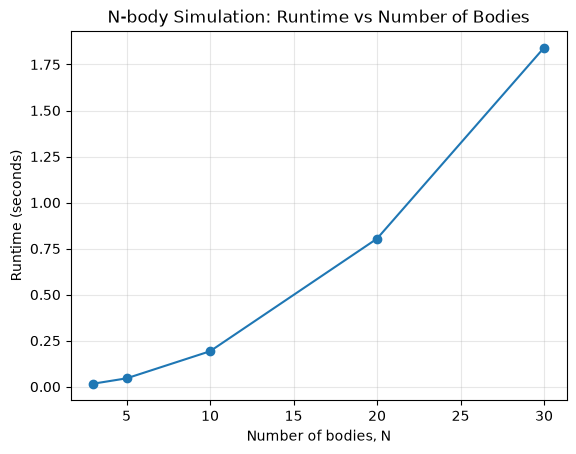

In [47]:
# This timing test uses artificial initial conditions and equal masses to investigate computational cost, rather than realistic planetary dynamics
import time 

# Choose the numbers of bodies to test
N_values = [3, 5, 10, 20, 30]

# Create an empty list to store the runtime for each simulation
runtimes = []

# Use the same timestep and number of simulation steps for every test
timestep = 3600
t_tot = timestep * 100  # Run 100 steps per simulation

# Repeat the test for each number of bodies
for N_test in N_values:

    # Create initial conditions for N_test bodies
    positions_test = np.zeros((N_test, 2))
    velocities_test = np.zeros((N_test, 2))
    masses_test = np.full(N_test, 1e20)

    # Place the bodies at different positions to avoid zero separation
    for i in range(N_test):
        positions_test[i] = [i * 1e10, 0]

    # Measure how long the simulation takes
    start = time.perf_counter()

    run_simulation(
        positions_test.copy(),
        velocities_test.copy(),
        masses_test,
        timestep,
        t_tot
    )
    end = time.perf_counter()

    # Store the runtime for this number of bodies
    runtime = end - start
    runtimes.append(runtime)
    print("Number of bodies:", N_test, "| Runtime:", runtime, "seconds")


# Plot runtime against the number of bodies
plt.plot(N_values, runtimes, 'o-')
plt.xlabel("Number of bodies, N")
plt.ylabel("Runtime (seconds)")
plt.title("N-body Simulation: Runtime vs Number of Bodies")
plt.grid(True, alpha=0.3)
plt.show()

From this graph, the runtime increases with the number of bodies because each body's acceleration must be calculated by considering its gravitational interaction with every other body. Consequently, the computational cost grows approximately as $N^2$, causing the simulation to take progressively longer as more bodies are added.


#### Conclusion



This project developed a gravitational simulation from a two-body Sun–Earth system into a generalised N-body model using Python. Comparing Euler’s method with fourth-order Runge–Kutta demonstrated how the choice of numerical integration method and timestep affects orbital accuracy and the conservation of energy and angular momentum. The N-body extension showed how the physical model can be generalised using arrays and nested loops, while the runtime investigation illustrated the increasing computational cost as the number of bodies grows.

Overall, the project combined physical modelling, numerical methods, programming and data analysis to investigate the accuracy and computational efficiency of gravitational simulations.
